# TASK 7: VISUALISASI DASHBOARD DATASET KUNJUNGAN RAWAT JALAN

**Divisi:** Data Analyst  |  **Program:** Magang Vinix7 (PT. Vinix Seven Aurum)

### Disusun oleh Kelompok 29:
* Satrio Faza Mubarok
* Diki Prasetia Dekanata
* Nadhif Dobry Alvaro
* Ayusti Nur Utami
* Farhan Ridwan Badhawi
* Josephine Marcelia


## 1. Import & Load Data

In [14]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.1f}'.format)

# Ambang durasi tunggu ekstrem (menit), dijustifikasi di bagian 2
AMBANG_EKSTREM = 150

try:
    from google.colab import files
    up = files.upload()
    PATH = list(up.keys())[0]
except ImportError:
    PATH = 'rs_knjngn_rawat_jln.csv'

raw = pd.read_csv(PATH)
print(raw.shape)
raw.head()

Saving rs_knjngn_rawat_jln.csv to rs_knjngn_rawat_jln (1).csv
(5525, 6)


,no_rm,kd_poli,kategori_usia,metode_bayar,waktu_registrasi,durasi_tunggu_mnt
0,RM-401953,Spesialis Jantung,Lansia,Umum,2026-03-28 11:04:00,62.0
1,RM-189464,Poli Umum,Dewasa,BPJS,2026-03-16 14:56:00,56.0
2,RM-824839,Poli Gigi,Remaja,bpjs,2026-03-04 07:24:00,60.0
3,RM-985155,Poli Gigi,Lansia,Umum,2026-03-10 10:41:00,37.0
4,RM-468226,Poli Umum,Dewasa,Umum,2026-03-04 08:05:00,20.0


## 2. Audit Data Mentah (Anomali Finding)

In [15]:
print('--- Info & tipe data ---'); raw.info()
print('\n--- Missing value ---'); print(raw.isna().sum())
print('\n--- Duplikat baris penuh :', raw.duplicated().sum())
print('--- no_rm yang muncul >1x   :', raw['no_rm'].duplicated().sum(), '(kemungkinan kunjungan ulang, cek di bawah)')
for c in ['kd_poli','kategori_usia','metode_bayar']:
    print(f'\n--- Nilai unik {c} ---'); print(raw[c].value_counts(dropna=False))
print('\n--- Statistik durasi_tunggu_mnt ---'); print(raw['durasi_tunggu_mnt'].describe())

--- Info & tipe data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5525 entries, 0 to 5524
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   no_rm              5525 non-null   object 
 1   kd_poli            5525 non-null   object 
 2   kategori_usia      5504 non-null   object 
 3   metode_bayar       5525 non-null   object 
 4   waktu_registrasi   5525 non-null   object 
 5   durasi_tunggu_mnt  5509 non-null   float64
dtypes: float64(1), object(5)
memory usage: 259.1+ KB

--- Missing value ---
no_rm                 0
kd_poli               0
kategori_usia        21
metode_bayar          0
waktu_registrasi      0
durasi_tunggu_mnt    16
dtype: int64

--- Duplikat baris penuh : 25
--- no_rm yang muncul >1x   : 37 (kemungkinan kunjungan ulang, cek di bawah)

--- Nilai unik kd_poli ---
kd_poli
Poli Anak            1732
Poli Umum            1711
Spesialis Dalam       850
Poli Gigi             739
Spe

In [16]:
# Cek apakah no_rm berulang = duplikat sungguhan atau kunjungan ulang (beda waktu registrasi)
dup_rm = raw[raw['no_rm'].duplicated(keep=False)].sort_values('no_rm')
print('Baris dengan no_rm berulang:', len(dup_rm))
print('Dari itu, yang IDENTIK di semua kolom:', dup_rm.duplicated(keep=False).sum())
dup_rm.head(10)

Baris dengan no_rm berulang: 74
Dari itu, yang IDENTIK di semua kolom: 50


,no_rm,kd_poli,kategori_usia,metode_bayar,waktu_registrasi,durasi_tunggu_mnt
2825,RM-110651,Poli Umum,Lansia,BPJS,2026-03-22 10:13:00,37.0
4722,RM-110651,Poli Umum,Lansia,BPJS,2026-03-22 10:13:00,37.0
686,RM-119816,Poli Umum,Dewasa,Asuransi,2026-03-12 09:48:00,57.0
636,RM-119816,Poli Gigi,Dewasa,Umum,2026-03-11 13:07:00,41.0
4012,RM-199239,Poli Umum,Remaja,BPJS,2026-03-20 09:52:00,48.0
296,RM-199239,Poli Umum,Remaja,BPJS,2026-03-20 09:52:00,48.0
2413,RM-212217,Spesialis Jantung,Dewasa,BPJS,2026-03-25 15:01:00,88.0
4779,RM-212217,Poli Gigi,Dewasa,BPJS,2026-03-01 11:54:00,55.0
4020,RM-250158,Poli Anak,Balita,BPJS,2026-03-06 15:10:00,40.0
5217,RM-250158,Poli Anak,Balita,BPJS,2026-03-06 15:10:00,40.0


**Catatan penting soal outlier:** durasi tunggu ekstrem (>150 menit) *tidak boleh langsung dibuang*. Bisa jadi itu justru sinyal masalah yang ditanyakan di Pertanyaan No. 4. Dicek dulu polanya sebelum memutuskan.

0.5    49.0
0.9    77.2
0.9    87.0
1.0   155.0
Name: durasi_tunggu_mnt, dtype: float64

Median = 49 mnt  ->  3 x median = 147 mnt
Persentil ke-99 = 155 mnt
Ambang yang dipakai = 150 mnt

Durasi > 150 mnt : 64
Durasi <= 0 / tidak masuk akal : 0


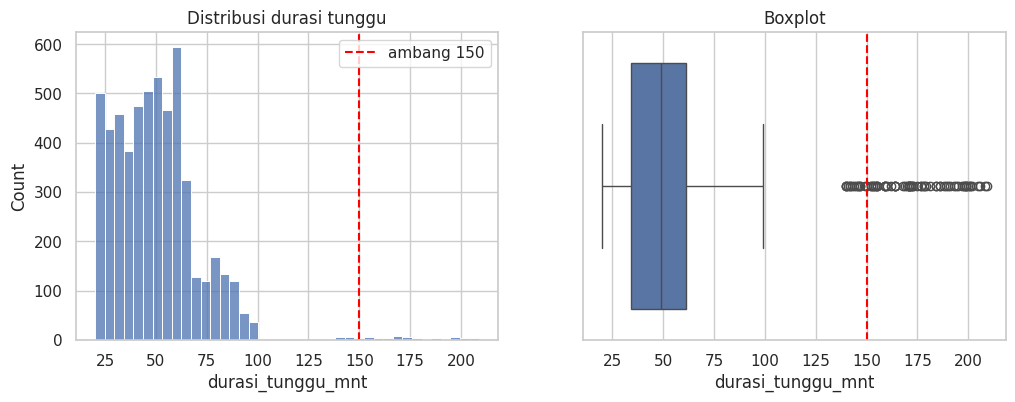

In [17]:
med = raw['durasi_tunggu_mnt'].median()                      # BARU
p99 = raw['durasi_tunggu_mnt'].quantile(.99)                 # BARU
print(raw['durasi_tunggu_mnt'].quantile([.5,.9,.95,.99]))
print(f'\nMedian = {med:.0f} mnt  ->  3 x median = {3*med:.0f} mnt')   # BARU
print(f'Persentil ke-99 = {p99:.0f} mnt')                              # BARU
print(f'Ambang yang dipakai = {AMBANG_EKSTREM} mnt')                   # BARU
print(f'\nDurasi > {AMBANG_EKSTREM} mnt :', (raw['durasi_tunggu_mnt']>AMBANG_EKSTREM).sum())
print('Durasi <= 0 / tidak masuk akal :', (raw['durasi_tunggu_mnt']<=0).sum())

fig,ax = plt.subplots(1,2,figsize=(12,4))
sns.histplot(raw['durasi_tunggu_mnt'].dropna(), bins=40, ax=ax[0])
ax[0].axvline(AMBANG_EKSTREM, c='red', ls='--', label=f'ambang {AMBANG_EKSTREM}')   # BARU
ax[0].legend(); ax[0].set_title('Distribusi durasi tunggu')
sns.boxplot(x=raw['durasi_tunggu_mnt'], ax=ax[1])
ax[1].axvline(AMBANG_EKSTREM, c='red', ls='--'); ax[1].set_title('Boxplot')            # BARU
plt.show()

## 3. Data Cleaning

In [18]:
df = raw.copy()
log_rows = []   # BARU: list, nanti dijadikan tabel
def catat(langkah, jumlah, keterangan=''):                                        # BARU
    log_rows.append({'Langkah': langkah, 'Jumlah baris': int(jumlah), 'Keterangan': keterangan})

catat('Baris awal', len(df))

# 3.1 Standarisasi teks
sebelum = df[['kd_poli','kategori_usia','metode_bayar','no_rm']].copy()           # BARU: snapshot sebelum diubah

df['kd_poli']       = df['kd_poli'].str.strip().str.title()
df['kategori_usia'] = df['kategori_usia'].str.strip().str.title()
df['metode_bayar']  = df['metode_bayar'].str.replace(r'\s+', '', regex=True).str.upper()
df['metode_bayar']  = df['metode_bayar'].replace({'UMUM':'Umum','ASURANSI':'Asuransi'})   # BPJS tetap kapital
df['no_rm']         = df['no_rm'].str.strip().str.upper()

# BARU: hitung baris yang benar-benar berubah, dirinci nilai asli -> nilai baru
rincian = []
for c in sebelum.columns:
    berubah = sebelum[c].notna() & (sebelum[c] != df[c])
    if berubah.any():
        r = (pd.DataFrame({'kolom': c, 'nilai_asli': sebelum.loc[berubah, c], 'menjadi': df.loc[berubah, c]})
               .value_counts().reset_index(name='jumlah_baris'))
        rincian.append(r)
        catat(f'Penyeragaman teks: {c}', berubah.sum(), 'huruf besar/kecil, spasi menyelip')
rincian = pd.concat(rincian, ignore_index=True) if rincian else pd.DataFrame()
baris_diseragamkan = (sebelum.notna() & (sebelum != df[sebelum.columns])).any(axis=1).sum()
catat('Total baris yang diseragamkan (unik)', baris_diseragamkan, 'baris dengan >=1 kolom teks berubah')

# 3.2 Tipe data
df['waktu_registrasi'] = pd.to_datetime(df['waktu_registrasi'], errors='coerce')
catat('waktu_registrasi tidak valid', df['waktu_registrasi'].isna().sum())

# 3.3 Duplikat (kunjungan ulang dengan waktu beda dipertahankan)
before = len(df); df = df.drop_duplicates().reset_index(drop=True)
catat('Duplikat penuh dihapus', before - len(df))
catat('no_rm berulang (kunjungan ulang) dipertahankan', df['no_rm'].duplicated().sum(), 'beda waktu registrasi')

# 3.4 Missing value
catat('Null durasi_tunggu_mnt', df['durasi_tunggu_mnt'].isna().sum())
before = len(df); df = df.dropna(subset=['durasi_tunggu_mnt','waktu_registrasi']).reset_index(drop=True)
catat('Baris null durasi/waktu dihapus', before - len(df))

catat('Null kategori_usia diisi "Tidak Diketahui"', df['kategori_usia'].isna().sum(), 'baris tetap dipakai utk tren & metode bayar')
df['kategori_usia'] = df['kategori_usia'].fillna('Tidak Diketahui')

# 3.5 Durasi tidak valid dibuang; outlier tinggi hanya DI-FLAG
before = len(df); df = df[df['durasi_tunggu_mnt'] > 0]; catat('Durasi <= 0 dihapus', before - len(df))
df['durasi_tunggu_mnt'] = df['durasi_tunggu_mnt'].astype(int)
df['flag_ekstrem'] = np.where(df['durasi_tunggu_mnt'] > AMBANG_EKSTREM, f'Ekstrem (>{AMBANG_EKSTREM} mnt)', 'Normal')
catat(f'Durasi ekstrem (>{AMBANG_EKSTREM} mnt) di-flag, DIPERTAHANKAN', (df['flag_ekstrem'] != 'Normal').sum(), 'sinyal bisnis, bukan salah input')

catat('Baris akhir', len(df))

tabel_log = pd.DataFrame(log_rows)                                               # BARU: tabel rapi
print('=== LOG PEMBERSIHAN DATA ===')
display(tabel_log)
print('\n=== RINCIAN PENYERAGAMAN TEKS (nilai asli -> nilai baru) ===')
display(rincian)
print('\nNilai unik setelah cleaning:')
for c in ['kd_poli','kategori_usia','metode_bayar']: print(c, '->', sorted(df[c].unique()))

=== LOG PEMBERSIHAN DATA ===


,Langkah,Jumlah baris,Keterangan
0,Baris awal,5525,
1,Penyeragaman teks: kd_poli,51,"huruf besar/kecil, spasi menyelip"
2,Penyeragaman teks: metode_bayar,153,"huruf besar/kecil, spasi menyelip"
3,Total baris yang diseragamkan (unik),204,baris dengan >=1 kolom teks berubah
4,waktu_registrasi tidak valid,0,
5,Duplikat penuh dihapus,25,
6,no_rm berulang (kunjungan ulang) dipertahankan,12,beda waktu registrasi
7,Null durasi_tunggu_mnt,16,
8,Baris null durasi/waktu dihapus,16,
9,"Null kategori_usia diisi ""Tidak Diketahui""",21,baris tetap dipakai utk tren & metode bayar



=== RINCIAN PENYERAGAMAN TEKS (nilai asli -> nilai baru) ===


,kolom,nilai_asli,menjadi,jumlah_baris
0,kd_poli,poli gigi,Poli Gigi,51
1,metode_bayar,B P J S,BPJS,51
2,metode_bayar,UMUM,Umum,51
3,metode_bayar,bpjs,BPJS,51



Nilai unik setelah cleaning:
kd_poli -> ['Poli Anak', 'Poli Gigi', 'Poli Umum', 'Spesialis Dalam', 'Spesialis Jantung']
kategori_usia -> ['Balita', 'Dewasa', 'Lansia', 'Remaja', 'Tidak Diketahui']
metode_bayar -> ['Asuransi', 'BPJS', 'Umum']


## 4. Feature Engineering (kolom bantu untuk filter & chart di Looker Studio)

In [19]:
hari_map = {0:'Senin',1:'Selasa',2:'Rabu',3:'Kamis',4:'Jumat',5:'Sabtu',6:'Minggu'}
df['tanggal']       = df['waktu_registrasi'].dt.normalize()
df['tanggal_ymd']   = df['tanggal'].dt.strftime('%Y%m%d')   # BARU: aman dibaca Looker Studio sebagai Date
df['jam']           = df['waktu_registrasi'].dt.hour
df['no_hari']       = df['waktu_registrasi'].dt.dayofweek
df['nama_hari']     = df['no_hari'].map(hari_map)
df['sesi']          = np.where(df['jam'] < 12, 'Pagi (<12.00)', 'Siang (>=12.00)')
df['jumlah_pasien'] = 1

print('Jam registrasi yang ada di data:', sorted(int(j) for j in df['jam'].unique()))   # BARU
print('Jam 12 ada di data?', 12 in df['jam'].values)                                    # BARU
df.head()

Jam registrasi yang ada di data: [7, 8, 9, 10, 11, 13, 14, 15]
Jam 12 ada di data? False


,no_rm,kd_poli,kategori_usia,metode_bayar,waktu_registrasi,durasi_tunggu_mnt,flag_ekstrem,tanggal,tanggal_ymd,jam,no_hari,nama_hari,sesi,jumlah_pasien
0,RM-401953,Spesialis Jantung,Lansia,Umum,2026-03-28 11:04:00,62,Normal,2026-03-28,20260328,11,5,Sabtu,Pagi (<12.00),1
1,RM-189464,Poli Umum,Dewasa,BPJS,2026-03-16 14:56:00,56,Normal,2026-03-16,20260316,14,0,Senin,Siang (>=12.00),1
2,RM-824839,Poli Gigi,Remaja,BPJS,2026-03-04 07:24:00,60,Normal,2026-03-04,20260304,7,2,Rabu,Pagi (<12.00),1
3,RM-985155,Poli Gigi,Lansia,Umum,2026-03-10 10:41:00,37,Normal,2026-03-10,20260310,10,1,Selasa,Pagi (<12.00),1
4,RM-468226,Poli Umum,Dewasa,Umum,2026-03-04 08:05:00,20,Normal,2026-03-04,20260304,8,2,Rabu,Pagi (<12.00),1


## 5. Analisis untuk Menjawab 4 Pertanyaan Bisnis
**Penetapan ambang ekstrem = 150 menit.** Angka ini dipilih karena (1) hampir sama dengan persentil ke-99
(155 mnt) dan (2) sekitar 3× median (147 mnt), sehingga hanya menandai kasus yang *benar-benar* ekstrem
(64 baris dari 5.509 data valid), bukan sekadar pasien yang menunggu agak lama. Kasus ini **tidak dibuang**
karena polanya dibutuhkan untuk menjawab Pertanyaan No. 4.

### Q1. Tren kunjungan harian & hari yang melonjak
**Temuan Q1:** rata-rata 176,9 pasien/hari. Puncak 209 pasien terjadi pada 22 dan 29 Maret (keduanya Minggu).
Per hari dalam seminggu, Sabtu tertinggi (184,5) dan Senin terendah (169,8); selisih hanya sekitar 8%,
sehingga **tidak ada hari yang melonjak secara dramatis**. Tiap hari dalam seminggu hanya punya 4-5 sampel,
jadi pola mingguan jangan disimpulkan terlalu kuat.

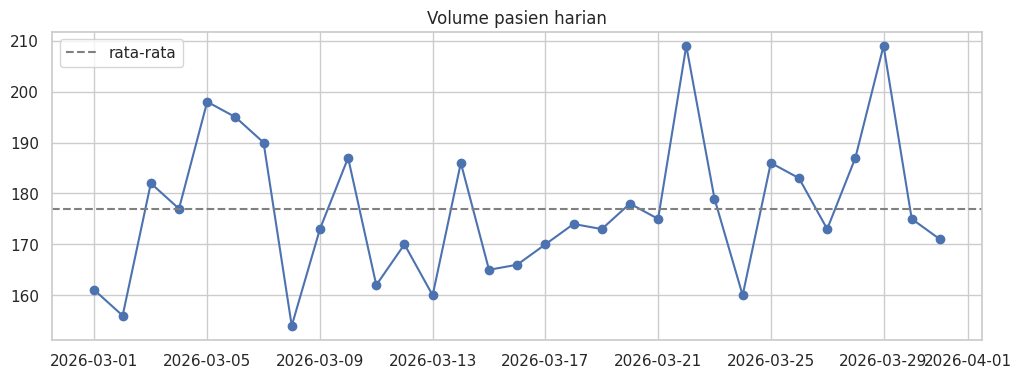

Rata-rata pasien per hari dalam seminggu:
nama_hari
Senin    169.8
Selasa   174.0
Rabu     174.8
Kamis    181.0
Jumat    176.5
Sabtu    184.5
Minggu   179.6
Name: pasien, dtype: float64


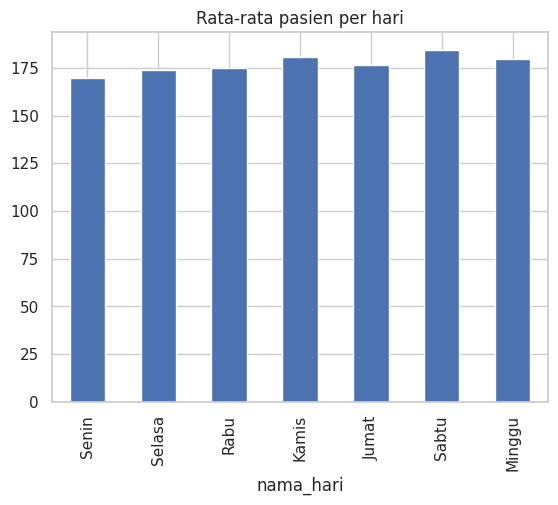

Tanggal tertinggi:
      tanggal  pasien nama_hari
21 2026-03-22     209    Minggu
28 2026-03-29     209    Minggu
4  2026-03-05     198     Kamis
5  2026-03-06     195     Jumat
6  2026-03-07     190     Sabtu

Puncak: 209 pasien pada 22 Mar 2026 (Minggu), 29 Mar 2026 (Minggu), 18% di atas rata-rata 176.9


In [20]:
harian = df.groupby('tanggal').size().rename('pasien').reset_index()
harian['nama_hari'] = harian['tanggal'].dt.dayofweek.map(hari_map)
rata_harian = harian['pasien'].mean()                                   # BARU: disimpan ke variabel

fig,ax = plt.subplots(figsize=(12,4)); ax.plot(harian['tanggal'], harian['pasien'], marker='o')
ax.axhline(rata_harian, ls='--', c='gray', label='rata-rata'); ax.legend(); ax.set_title('Volume pasien harian'); plt.show()

per_hari = harian.groupby('nama_hari')['pasien'].mean().reindex(list(hari_map.values()))
print('Rata-rata pasien per hari dalam seminggu:'); print(per_hari)
per_hari.plot.bar(title='Rata-rata pasien per hari'); plt.show()
print('Tanggal tertinggi:'); print(harian.nlargest(5,'pasien'))

maks   = harian['pasien'].max()
puncak = harian[harian['pasien'] == maks]          # bisa lebih dari 1 tanggal (kembar)
tgl    = ', '.join(f"{r.tanggal:%d %b %Y} ({r.nama_hari})" for r in puncak.itertuples())
print(f"\nPuncak: {maks} pasien pada {tgl}, "
      f"{(maks/rata_harian-1)*100:.0f}% di atas rata-rata {rata_harian:.1f}")

### Q2. Rasio pasien berdasarkan metode bayar
**Temuan Q2:** BPJS 63,9%, Umum 26,1%, Asuransi 9,9%. Hampir dua pertiga pasien menggunakan BPJS.

              jumlah  persen
metode_bayar                
BPJS            3507    63.9
Umum            1434    26.1
Asuransi         543     9.9


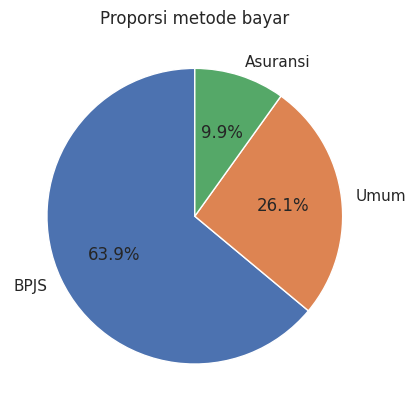

In [21]:
mb = df['metode_bayar'].value_counts(); print(pd.DataFrame({'jumlah':mb,'persen':(mb/mb.sum()*100)}))
mb.plot.pie(autopct='%1.1f%%',startangle=90,ylabel=''); plt.title('Proporsi metode bayar'); plt.show()

### Q3. Poliklinik dengan rata-rata waktu tunggu terlama
**Temuan Q3:** berdasarkan rata-rata, **Spesialis Dalam (78,4 mnt)** terlama, tetapi hanya unggul tipis dari
Spesialis Jantung (77,4 mnt); tiga poli lain sekitar 42 mnt. Berdasarkan median, urutannya terbalik
(Jantung 78, Dalam 71) karena rata-rata Spesialis Dalam terdongkrak 62 kasus ekstrem. Jadi keunggulan
Spesialis Dalam sebagian dipengaruhi outlier.

                   rata2  median     n  rata2_tanpa_ekstrem  n_ekstrem  \
kd_poli                                                                  
Spesialis Dalam     78.4    71.0   848                 70.5         62   
Spesialis Jantung   77.4    78.0   438                 77.4          0   
Poli Gigi           42.9    42.0   781                 42.6          2   
Poli Umum           42.2    42.0  1700                 42.2          0   
Poli Anak           41.9    42.0  1717                 41.9          0   

                   selisih_rata2_median  
kd_poli                                  
Spesialis Dalam                     7.4  
Spesialis Jantung                  -0.6  
Poli Gigi                           0.9  
Poli Umum                           0.2  
Poli Anak                          -0.1  


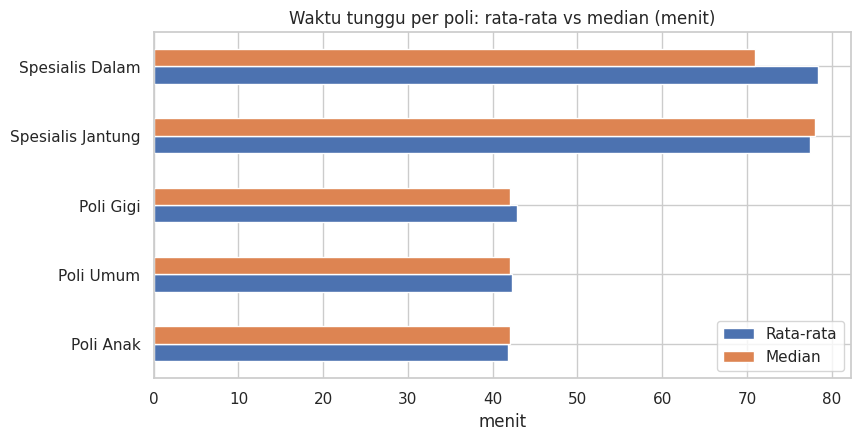

Poli teratas berdasarkan RATA-RATA: Spesialis Dalam
Poli teratas berdasarkan MEDIAN   : Spesialis Jantung
-> Peringkat berubah: posisi teratas menurut rata-rata dipengaruhi outlier.


In [22]:
poli = (df.groupby('kd_poli')['durasi_tunggu_mnt']
          .agg(rata2='mean', median='median', n='count')
          .sort_values('rata2', ascending=False))
poli['rata2_tanpa_ekstrem'] = df[df['flag_ekstrem']=='Normal'].groupby('kd_poli')['durasi_tunggu_mnt'].mean()   # BARU
poli['n_ekstrem'] = df[df['flag_ekstrem']!='Normal'].groupby('kd_poli').size()                                 # BARU
poli['n_ekstrem'] = poli['n_ekstrem'].fillna(0).astype(int)
poli['selisih_rata2_median'] = poli['rata2'] - poli['median']                                                  # BARU
print(poli)

# BARU: rata-rata DAN median berdampingan
plot_df = poli[['rata2','median']].sort_values('rata2').rename(columns={'rata2':'Rata-rata','median':'Median'})
ax = plot_df.plot.barh(figsize=(9,4.5), title='Waktu tunggu per poli: rata-rata vs median (menit)')
ax.set_xlabel('menit'); ax.set_ylabel(''); plt.show()

# BARU: cek apakah peringkat teratas berubah
top_mean   = poli['rata2'].idxmax()
top_median = poli['median'].idxmax()
print(f'Poli teratas berdasarkan RATA-RATA: {top_mean}')
print(f'Poli teratas berdasarkan MEDIAN   : {top_median}')
if top_mean != top_median:
    print('-> Peringkat berubah: posisi teratas menurut rata-rata dipengaruhi outlier.')

### Q4. Isu: Lansia + BPJS + pagi hari → waktu tunggu ekstrem?
**Temuan Q4: isu TERBUKTI di Spesialis Dalam.** Pasien Lansia + BPJS di sesi pagi (93 kasus) rata-rata menunggu
**151,9 mnt**, sedangkan pasien lain 69,3 mnt (sekitar 2,2×, selisih 82,6 mnt). Sebanyak 61 dari 93 kasus melewati
150 mnt. Kelompok Lansia yang sama di sesi siang normal (70,6 mnt), dan Lansia dengan Umum/Asuransi di poli yang
sama juga normal (sekitar 68-71 mnt), jadi masalahnya ada pada **kombinasi Lansia + BPJS + pagi**. Kasus ekstrem
hanya terjadi pada registrasi jam 07-10 (rata-rata sekitar 170-173 mnt); jam 11 sudah normal (63 mnt).

**Filter di dashboard:** kategori_usia = Lansia, metode_bayar = BPJS, sesi = Pagi (atau jam 7-10), lalu bandingkan per kd_poli.

In [23]:
lb_pagi  = df[(df['kategori_usia']=='Lansia') & (df['metode_bayar']=='BPJS') & (df['sesi'].str.startswith('Pagi'))]
lb_siang = df[(df['kategori_usia']=='Lansia') & (df['metode_bayar']=='BPJS') & (df['sesi'].str.startswith('Siang'))]   # BARU
pembanding = df[~df.index.isin(lb_pagi.index)]

C_LB, C_N, C_SGNG, C_LAIN = 'Lansia-BPJS-Pagi (rata2)', 'Jumlah kasus', 'Lansia-BPJS-Siang (rata2)', 'Pasien lain (rata2)'

semua_poli = sorted(df['kd_poli'].unique())                                      # BARU
t = pd.DataFrame({
    C_LB:   lb_pagi.groupby('kd_poli')['durasi_tunggu_mnt'].mean(),
    C_N:    lb_pagi.groupby('kd_poli')['durasi_tunggu_mnt'].size(),
    C_SGNG: lb_siang.groupby('kd_poli')['durasi_tunggu_mnt'].mean(),             # BARU
    C_LAIN: pembanding.groupby('kd_poli')['durasi_tunggu_mnt'].mean(),
}).reindex(semua_poli)                                                           # BARU: Poli Anak tetap tampil (NaN)
t[C_N] = t[C_N].fillna(0).astype(int)

# BARU: pakai NAMA kolom, bukan t.iloc[:,0]
t['Selisih vs lain (mnt)']        = t[C_LB] - t[C_LAIN]
t['Kali lipat vs lain']           = t[C_LB] / t[C_LAIN]
t['Selisih vs Lansia-BPJS siang'] = t[C_LB] - t[C_SGNG]
print(t.sort_values('Selisih vs lain (mnt)', ascending=False))

tanpa_kasus = t.index[t[C_N] == 0].tolist()                                      # BARU: catatan NaN
if tanpa_kasus:
    print(f'\nCATATAN: {tanpa_kasus} tidak punya pasien Lansia-BPJS-Pagi, sehingga NaN (bukan nol / bukan kesalahan).')

poli_kritis = t['Selisih vs lain (mnt)'].idxmax(); print('\nPoli dengan kesenjangan terbesar:', poli_kritis)

                   Lansia-BPJS-Pagi (rata2)  Jumlah kasus  \
kd_poli                                                     
Spesialis Dalam                       151.9            93   
Poli Gigi                              46.7            70   
Poli Umum                              43.6           177   
Spesialis Jantung                      75.8            51   
Poli Anak                               NaN             0   

                   Lansia-BPJS-Siang (rata2)  Pasien lain (rata2)  \
kd_poli                                                             
Spesialis Dalam                         70.6                 69.3   
Poli Gigi                               40.8                 42.5   
Poli Umum                               45.1                 42.1   
Spesialis Jantung                       77.5                 77.6   
Poli Anak                                NaN                 41.9   

                   Selisih vs lain (mnt)  Kali lipat vs lain  \
kd_poli                 

                               mean  median  max  count
sesi            kelompok                               
Pagi (<12.00)   Lainnya        69.8    70.0  154    492
                Lansia + BPJS 151.9   164.0  209     93
Siang (>=12.00) Lainnya        68.1    68.0   91    228
                Lansia + BPJS  70.6    69.0   91     35

Kondisi Lansia-BPJS lain (usia saja / BPJS saja / keduanya?)
metode_bayar     Asuransi  BPJS  Umum
kategori_usia                        
Dewasa               68.9  68.4  72.1
Lansia               68.4 129.7  71.2
Remaja               60.6  70.0  66.2
Tidak Diketahui       NaN   NaN  75.0

Lansia + BPJS di Spesialis Dalam, per jam registrasi:
     rata2  median   n  n_ekstrem
jam                              
7    169.7   172.0  17         12
8    173.5   171.0  23         21
9    172.0   166.5  14         13
10   171.4   177.5  22         15
11    63.2    60.0  17          0
13    76.2    84.5  10          0
14    71.8    79.5  12          0
15    65.2   

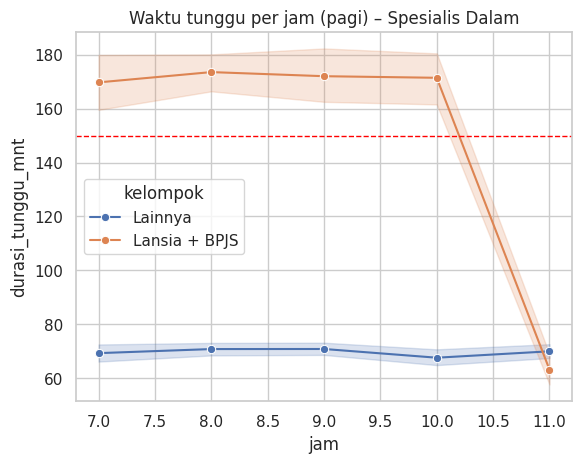


Kasus ekstrem (>150 mnt) – komposisi:
kd_poli          kategori_usia  metode_bayar  sesi         
Spesialis Dalam  Lansia         BPJS          Pagi (<12.00)    61
Poli Gigi        Lansia         BPJS          Pagi (<12.00)     2
Spesialis Dalam  Lansia         Umum          Pagi (<12.00)     1
dtype: int64


In [24]:
sub = df[df['kd_poli']==poli_kritis]
sub = sub.assign(kelompok=np.where((sub.kategori_usia=='Lansia')&(sub.metode_bayar=='BPJS'),'Lansia + BPJS','Lainnya'))
print(sub.groupby(['sesi','kelompok'])['durasi_tunggu_mnt'].agg(['mean','median','max','count']))

print('\nKondisi Lansia-BPJS lain (usia saja / BPJS saja / keduanya?)')
print(sub.groupby(['kategori_usia','metode_bayar'])['durasi_tunggu_mnt'].mean().unstack())

# ===== BARU: di jam berapa tepatnya waktu tunggu menjadi ekstrem? =====
lb_poli = sub[sub['kelompok']=='Lansia + BPJS']
per_jam = lb_poli.groupby('jam')['durasi_tunggu_mnt'].agg(rata2='mean', median='median', n='count')
per_jam['n_ekstrem'] = lb_poli[lb_poli['flag_ekstrem']!='Normal'].groupby('jam').size()
per_jam['n_ekstrem'] = per_jam['n_ekstrem'].fillna(0).astype(int)
print(f'\nLansia + BPJS di {poli_kritis}, per jam registrasi:'); print(per_jam)
jam_ekstrem = per_jam.index[per_jam['n_ekstrem']>0].tolist()
jam11 = per_jam['rata2'].get(11, float('nan'))     # aman kalau jam 11 tidak ada
print(f'Jam dengan kasus ekstrem: {jam_ekstrem}  |  Jam 11 rata-rata: {jam11:.0f} mnt')
# ======================================================================

pagi = sub[sub['sesi'].str.startswith('Pagi')]
sns.lineplot(data=pagi, x='jam', y='durasi_tunggu_mnt', hue='kelompok', estimator='mean', marker='o')
plt.axhline(AMBANG_EKSTREM, c='red', ls='--', lw=1)                              # BARU: garis ambang
plt.title(f'Waktu tunggu per jam (pagi) – {poli_kritis}'); plt.show()

print(f'\nKasus ekstrem (>{AMBANG_EKSTREM} mnt) – komposisi:')
print(df[df.flag_ekstrem!='Normal'].groupby(['kd_poli','kategori_usia','metode_bayar','sesi']).size().sort_values(ascending=False).head(5))

### Heatmap pendukung (poli × jam) untuk cek pola tambahan

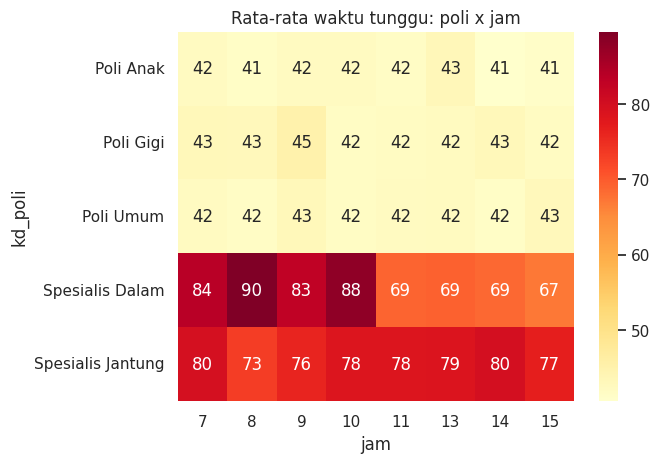

In [25]:
sns.heatmap(df.pivot_table(index='kd_poli',columns='jam',values='durasi_tunggu_mnt',aggfunc='mean'),annot=True,fmt='.0f',cmap='YlOrRd'); plt.title('Rata-rata waktu tunggu: poli x jam'); plt.show()

## 6. Export Data Bersih untuk Looker Studio

In [26]:
kolom = ['no_rm','waktu_registrasi','tanggal','tanggal_ymd','nama_hari','no_hari','jam','sesi',
         'kd_poli','kategori_usia','metode_bayar','durasi_tunggu_mnt','flag_ekstrem','jumlah_pasien']   # + tanggal_ymd
df[kolom].to_csv('data_bersih_rawat_jalan.csv', index=False)
print('Tersimpan:', len(df), 'baris')
try:
    files.download('data_bersih_rawat_jalan.csv')
except NameError:
    pass

Tersimpan: 5484 baris


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Ringkasan Log Pembersihan (untuk laporan PDF)
Salin angka dari tabel `tabel_log` dan `rincian` di sel **3. Data Cleaning** ke bagian **Log Pembersihan Data**:
jumlah duplikat dihapus, baris yang penulisannya diseragamkan beserta contoh variasinya (nilai asli → nilai baru),
null durasi dihapus, null usia diisi 'Tidak Diketahui', dan penjelasan bahwa outlier >150 menit **dipertahankan**
(hanya di-flag) karena merupakan sinyal bisnis, bukan kesalahan input.